In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load dataset
df = pd.read_csv("student-mat.csv", sep=";")

# Display first five rows
print("First 5 rows:")
display(df.head())


First 5 rows:


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10


In [35]:
!pip install imbalanced-learn

In [5]:

print("Number of rows and columns:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

print("\nStatistical summary:")
display(df.describe())


Number of rows and columns: (395, 33)

Column names:
['school', 'sex', 'age', 'address', 'famsize', 'Pstatus', 'Medu', 'Fedu', 'Mjob', 'Fjob', 'reason', 'guardian', 'traveltime', 'studytime', 'failures', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences', 'G1', 'G2', 'G3']

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 395 entries, 0 to 394
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   school      395 non-null    str  
 1   sex         395 non-null    str  
 2   age         395 non-null    int64
 3   address     395 non-null    str  
 4   famsize     395 non-null    str  
 5   Pstatus     395 non-null    str  
 6   Medu        395 non-null    int64
 7   Fedu        395 non-null    int64
 8   Mjob        395 non-null    str  
 9   Fjob        395 non-null    str  
 10  reason      395 non-null    st

,age,Medu,Fedu,traveltime,studytime,failures,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
count,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000
mean,16.696203,2.749367,2.521519,1.448101,2.035443,0.334177,3.944304,3.235443,3.108861,1.481013,2.291139,3.554430,5.708861,10.908861,10.713924,10.415190
std,1.276043,1.094735,1.088201,0.697505,0.839240,0.743651,0.896659,0.998862,1.113278,0.890741,1.287897,1.390303,8.003096,3.319195,3.761505,4.581443
min,15.000000,0.000000,0.000000,1.000000,1.000000,0.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,3.000000,0.000000,0.000000
25%,16.000000,2.000000,2.000000,1.000000,1.000000,0.000000,4.000000,3.000000,2.000000,1.000000,1.000000,3.000000,0.000000,8.000000,9.000000,8.000000
50%,17.000000,3.000000,2.000000,1.000000,2.000000,0.000000,4.000000,3.000000,3.000000,1.000000,2.000000,4.000000,4.000000,11.000000,11.000000,11.000000
75%,18.000000,4.000000,3.000000,2.000000,2.000000,0.000000,5.000000,4.000000,4.000000,2.000000,3.000000,5.000000,8.000000,13.000000,13.000000,14.000000
max,22.000000,4.000000,4.000000,4.000000,4.000000,3.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,75.000000,19.000000,19.000000,20.000000


In [6]:

missing_values = df.isnull().sum()

print("Missing values in each column:")
display(missing_values)

print("\nTotal missing values:", df.isnull().sum().sum())


Missing values in each column:


school        0
sex           0
age           0
address       0
famsize       0
Pstatus       0
Medu          0
Fedu          0
Mjob          0
Fjob          0
reason        0
guardian      0
traveltime    0
studytime     0
failures      0
schoolsup     0
famsup        0
paid          0
activities    0
nursery       0
higher        0
internet      0
romantic      0
famrel        0
freetime      0
goout         0
Dalc          0
Walc          0
health        0
absences      0
G1            0
G2            0
G3            0
dtype: int64


Total missing values: 0


In [7]:

duplicate_count = df.duplicated().sum()

print("Number of duplicate rows:", duplicate_count)


Number of duplicate rows: 0


In [8]:

numerical_cols = df.select_dtypes(include=np.number).columns.tolist()
categorical_cols = df.select_dtypes(include="object").columns.tolist()

print("Numerical columns:")
print(numerical_cols)

print("\nCategorical columns:")
print(categorical_cols)


Numerical columns:
['age', 'Medu', 'Fedu', 'traveltime', 'studytime', 'failures', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences', 'G1', 'G2', 'G3']

Categorical columns:
['school', 'sex', 'address', 'famsize', 'Pstatus', 'Mjob', 'Fjob', 'reason', 'guardian', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic']


C:\Users\AKASH\AppData\Local\Temp\ipykernel_11132\3521286399.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = df.select_dtypes(include="object").columns.tolist()


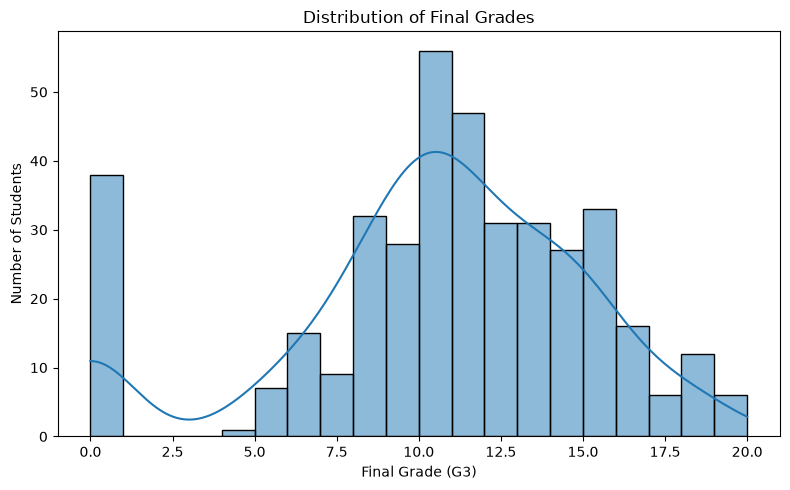

In [9]:

plt.figure(figsize=(8, 5))

sns.histplot(data=df, x="G3", bins=20, kde=True)

plt.title("Distribution of Final Grades")
plt.xlabel("Final Grade (G3)")
plt.ylabel("Number of Students")


plt.tight_layout()
plt.show()


Performance counts:


performance
High Performance    265
Low Performance     130
Name: count, dtype: int64


Performance percentages:


performance
High Performance    67.09
Low Performance     32.91
Name: proportion, dtype: float64

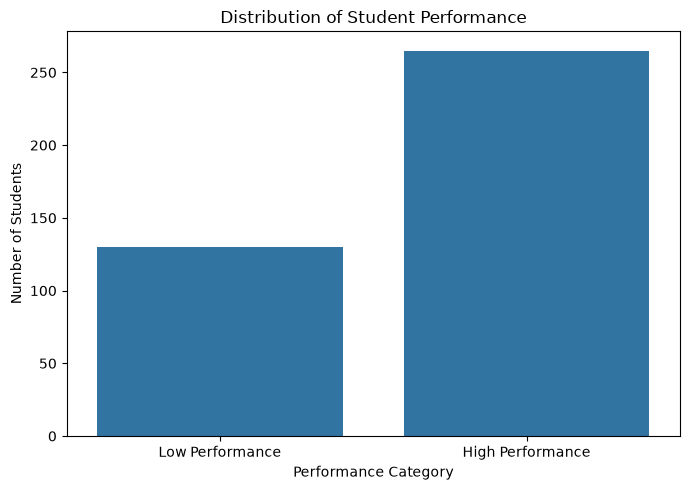

In [10]:

df["performance"] = np.where(
    df["G3"] < 10,
    "Low Performance",
    "High Performance"
)

print("Performance counts:")
display(df["performance"].value_counts())

print("\nPerformance percentages:")
display(
    (df["performance"].value_counts(normalize=True) * 100).round(2)
)

plt.figure(figsize=(7, 5))

sns.countplot(data=df, x="performance")

plt.title("Distribution of Student Performance")
plt.xlabel("Performance Category")
plt.ylabel("Number of Students")

plt.tight_layout()
plt.show()


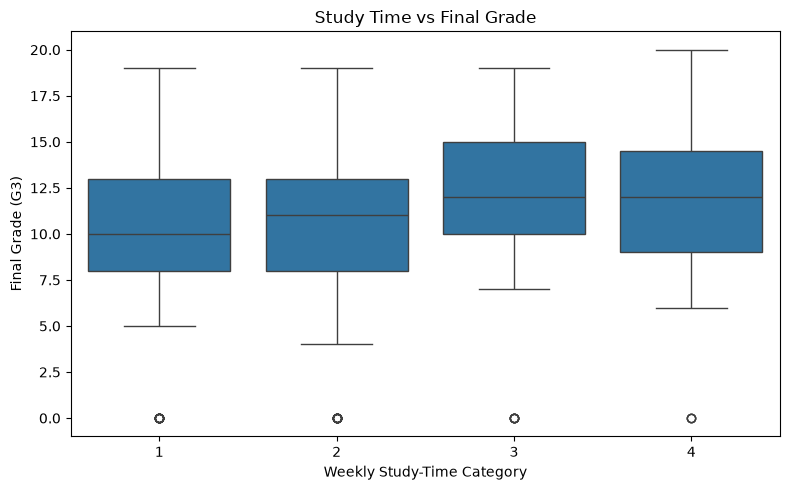

In [11]:

plt.figure(figsize=(8, 5))

sns.boxplot(data=df, x="studytime", y="G3")

plt.title("Study Time vs Final Grade")
plt.xlabel("Weekly Study-Time Category")
plt.ylabel("Final Grade (G3)")

plt.tight_layout()
plt.show()


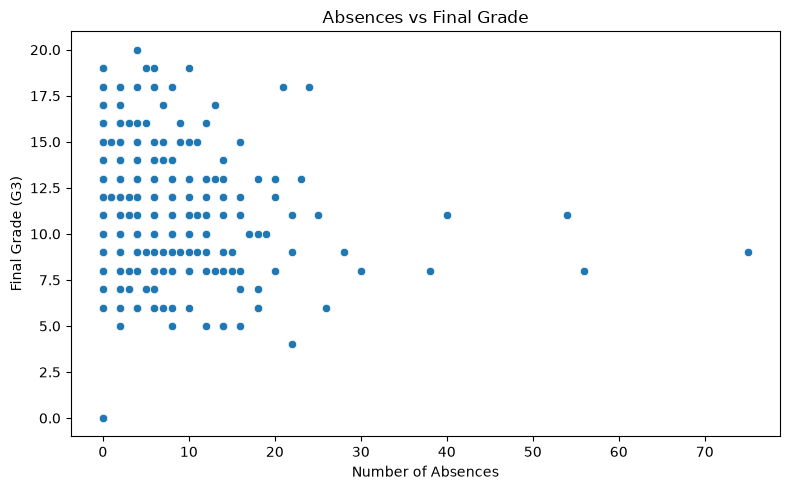

In [12]:

plt.figure(figsize=(8, 5))

sns.scatterplot(data=df, x="absences", y="G3")

plt.title("Absences vs Final Grade")
plt.xlabel("Number of Absences")
plt.ylabel("Final Grade (G3)")

plt.tight_layout()
plt.show()


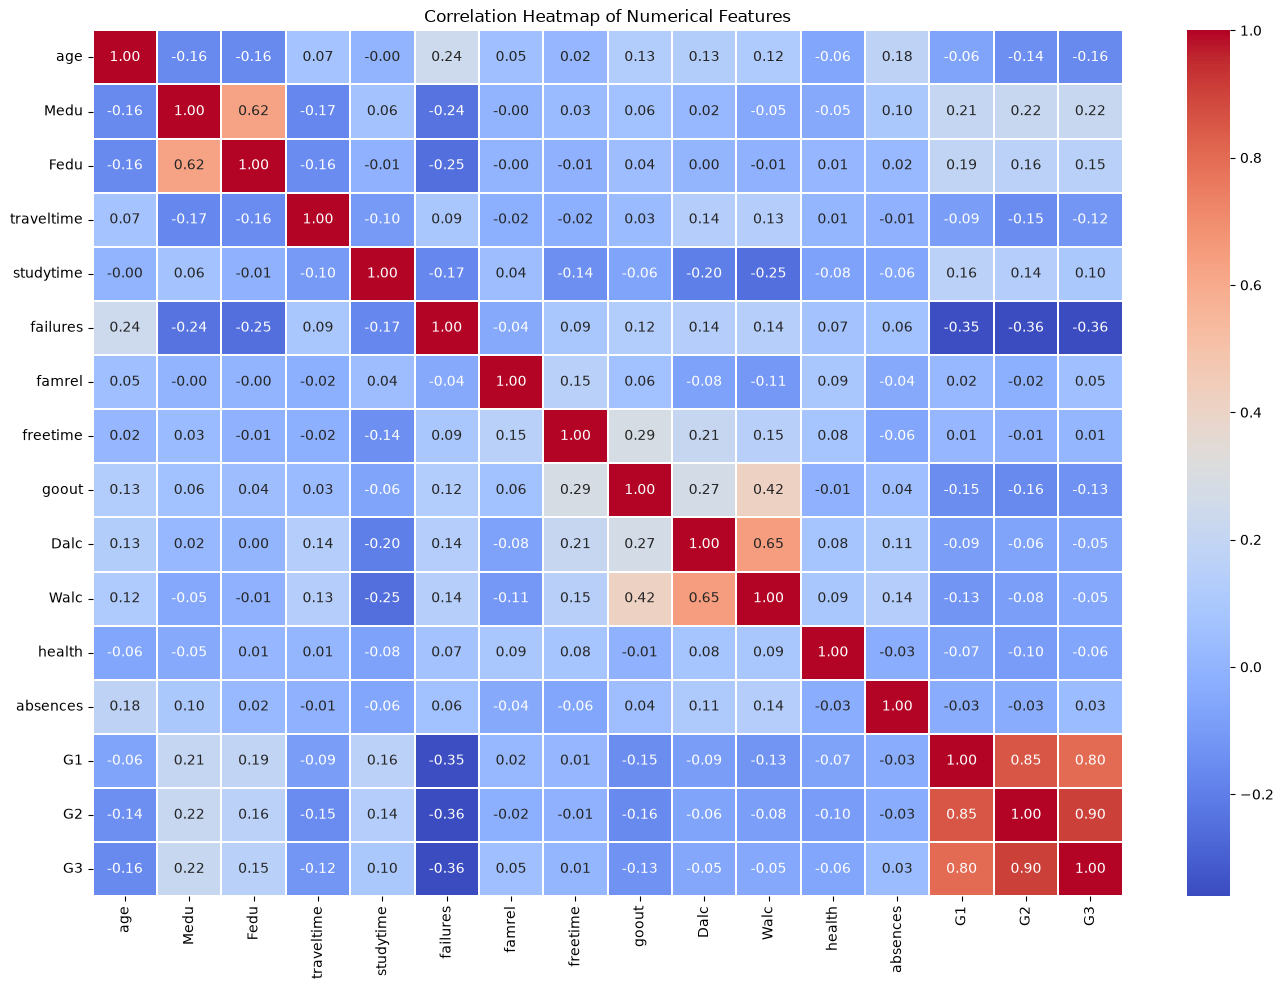

In [13]:

numeric_df = df.select_dtypes(include=np.number)

correlation_matrix = numeric_df.corr()

plt.figure(figsize=(14, 10))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    linewidths=0.3
)

plt.title("Correlation Heatmap of Numerical Features")
plt.tight_layout()
plt.show()


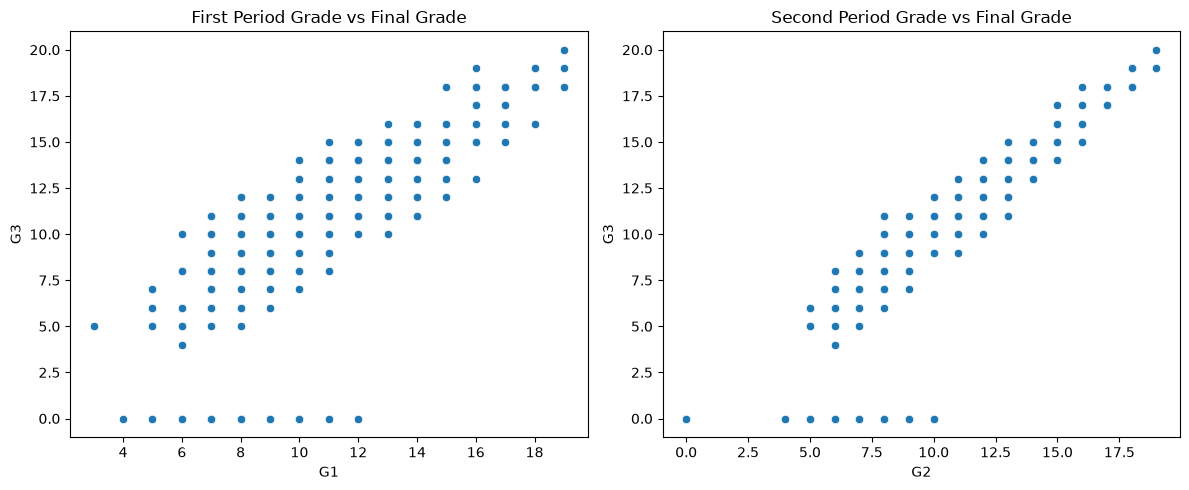

In [14]:

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.scatterplot(data=df, x="G1", y="G3", ax=axes[0])
axes[0].set_title("First Period Grade vs Final Grade")
axes[0].set_xlabel("G1")
axes[0].set_ylabel("G3")

sns.scatterplot(data=df, x="G2", y="G3", ax=axes[1])
axes[1].set_title("Second Period Grade vs Final Grade")
axes[1].set_xlabel("G2")
axes[1].set_ylabel("G3")

plt.tight_layout()
plt.show()


In [13]:

for col in categorical_cols:
    print(f"\n--- {col} ---")
    print(df[col].value_counts(dropna=False))



--- school ---
school
GP    349
MS     46
Name: count, dtype: int64

--- sex ---
sex
F    208
M    187
Name: count, dtype: int64

--- address ---
address
U    307
R     88
Name: count, dtype: int64

--- famsize ---
famsize
GT3    281
LE3    114
Name: count, dtype: int64

--- Pstatus ---
Pstatus
T    354
A     41
Name: count, dtype: int64

--- Mjob ---
Mjob
other       141
services    103
at_home      59
teacher      58
health       34
Name: count, dtype: int64

--- Fjob ---
Fjob
other       217
services    111
teacher      29
at_home      20
health       18
Name: count, dtype: int64

--- reason ---
reason
course        145
home          109
reputation    105
other          36
Name: count, dtype: int64

--- guardian ---
guardian
mother    273
father     90
other      32
Name: count, dtype: int64

--- schoolsup ---
schoolsup
no     344
yes     51
Name: count, dtype: int64

--- famsup ---
famsup
yes    242
no     153
Name: count, dtype: int64

--- paid ---
paid
no     214
yes    181
Name

In [15]:

print("Minimum values:")
display(df[numerical_cols].min())

print("\nMaximum values:")
display(df[numerical_cols].max())

print("\nUnique values in grade columns:")
for col in ["G1", "G2", "G3"]:
    print(col, sorted(df[col].unique()))


Minimum values:


age           15
Medu           0
Fedu           0
traveltime     1
studytime      1
failures       0
famrel         1
freetime       1
goout          1
Dalc           1
Walc           1
health         1
absences       0
G1             3
G2             0
G3             0
dtype: int64


Maximum values:


age           22
Medu           4
Fedu           4
traveltime     4
studytime      4
failures       3
famrel         5
freetime       5
goout          5
Dalc           5
Walc           5
health         5
absences      75
G1            19
G2            19
G3            20
dtype: int64


Unique values in grade columns:
G1 [np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12), np.int64(13), np.int64(14), np.int64(15), np.int64(16), np.int64(17), np.int64(18), np.int64(19)]
G2 [np.int64(0), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12), np.int64(13), np.int64(14), np.int64(15), np.int64(16), np.int64(17), np.int64(18), np.int64(19)]
G3 [np.int64(0), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12), np.int64(13), np.int64(14), np.int64(15), np.int64(16), np.int64(17), np.int64(18), np.int64(19), np.int64(20)]


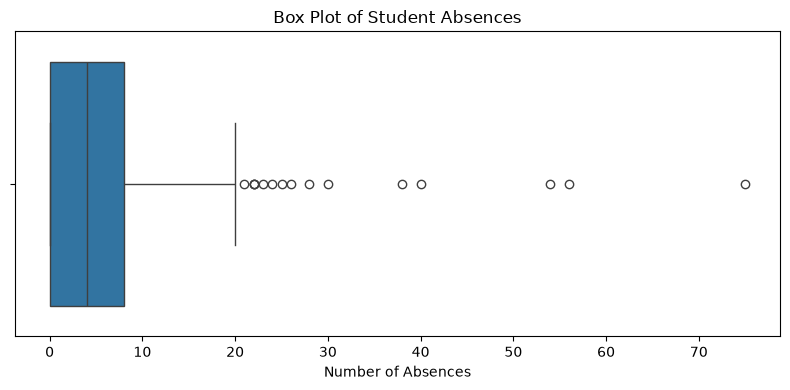

In [16]:

plt.figure(figsize=(8, 4))

sns.boxplot(x=df["absences"])

plt.title("Box Plot of Student Absences")
plt.xlabel("Number of Absences")

plt.tight_layout()
plt.show()


In [17]:

# Target: 0 = Low Performance, 1 = High Performance
df["performance"] = (df["G3"] >= 10).astype(int)
X = df.drop(columns=["G3", "performance", "G1", "G2"])
# Exclude G3 because it defines the target
X = df.drop(columns=["G3", "performance"])
y = df["performance"]

print("Input feature dimensions:", X.shape)
print("Target dimensions:", y.shape)

print("\nTarget distribution:")
print(y.value_counts())


Input feature dimensions: (395, 32)
Target dimensions: (395,)

Target distribution:
performance
1    265
0    130
Name: count, dtype: int64


In [18]:

df.to_csv("student_performance_processed.csv", index=False)

print("Processed dataset saved successfully.")


Processed dataset saved successfully.


In [19]:
print(df["school"].value_counts())
# Compare final grades between schools
print(df["performance"].value_counts())
print(df.groupby("school")["G3"].agg(
    ["count", "mean", "median", "std", "min", "max"]
).round(2))

school
GP    349
MS     46
Name: count, dtype: int64
performance
1    265
0    130
Name: count, dtype: int64
        count   mean  median   std  min  max
school                                      
GP        349  10.49    11.0  4.63    0   20
MS         46   9.85    10.0  4.24    0   19


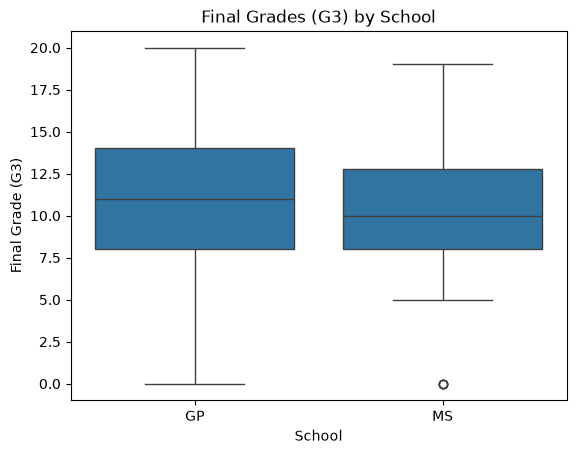

In [20]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.boxplot(data=df, x="school", y="G3")
plt.title("Final Grades (G3) by School")
plt.xlabel("School")
plt.ylabel("Final Grade (G3)")
plt.show()

## Baseline Model Implementation

Three supervised machine-learning models—KNN, Decision Tree, and Random Forest—are trained to classify student performance as Low (G3 < 10) or High (G3 >= 10). The dataset is split into 80% training data and 20% testing data. Numerical features are scaled, and categorical features are encoded using a preprocessing pipeline.

In [21]:
# Import required libraries
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, classification_report, confusion_matrix
)

# Define target
df["performance"]=(df["G3"]>=10).astype(int)
print("dataset after defining target\n",df.head(5))
# Separate features and target
X = df.drop(columns=["G3", "performance"])
y = df["performance"]

# Identify numerical and categorical features
numerical_cols = X.select_dtypes(include="number").columns.tolist()
categorical_cols = X.select_dtypes(include=["object", "str", "category"]).columns.tolist()

# Split data before fitting preprocessing
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])
print("Numerical features:", len(numerical_cols))
print("Categorical features:", len(categorical_cols))

dataset after defining target
   school sex  age address famsize Pstatus  Medu  Fedu     Mjob      Fjob  ...  \
0     GP   F   18       U     GT3       A     4     4  at_home   teacher  ...   
1     GP   F   17       U     GT3       T     1     1  at_home     other  ...   
2     GP   F   15       U     LE3       T     1     1  at_home     other  ...   
3     GP   F   15       U     GT3       T     4     2   health  services  ...   
4     GP   F   16       U     GT3       T     3     3    other     other  ...   

  freetime goout  Dalc  Walc  health absences  G1  G2  G3 performance  
0        3     4     1     1       3        6   5   6   6           0  
1        3     3     1     1       3        4   5   5   6           0  
2        3     2     2     3       3       10   7   8  10           1  
3        2     2     1     1       5        2  15  14  15           1  
4        3     2     1     2       5        4   6  10  10           1  

[5 rows x 34 columns]
Training samples: 316
Testi

In [22]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline

# Preprocess numerical and categorical features separately
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numerical_cols),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_cols)
    ]
)

print("Preprocessing pipeline created successfully.")


Preprocessing pipeline created successfully.


In [25]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
models = {
    "KNN": KNeighborsClassifier(),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(random_state=42),
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "SVM": SVC()
}

pipelines = {}

for name, model in models.items():
    pipeline=Pipeline([
        ("preprocessing", preprocessor),
        ("model", model)
    ])

    pipeline.fit(X_train,y_train)
    pipelines[name] = pipeline

    print(f"{name} trained successfully.")

KNN trained successfully.
Decision Tree trained successfully.
Random Forest trained successfully.
Logistic Regression trained successfully.
SVM trained successfully.


In [26]:
import pandas as pd
from sklearn.metrics import (
    accuracy_score, precision_score,
    recall_score, f1_score
)

results = []

for name, pipeline in pipelines.items():
    y_pred = pipeline.predict(X_test)
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1-Score": f1_score(y_test, y_pred, zero_division=0)
    })

results_df = pd.DataFrame(results)
display(results_df.round(3))

,Model,Accuracy,Precision,Recall,F1-Score
0,KNN,0.772,0.818,0.849,0.833
1,Decision Tree,0.861,0.977,0.811,0.887
2,Random Forest,0.873,0.957,0.849,0.900
3,Logistic Regression,0.873,0.957,0.849,0.900
4,SVM,0.861,0.920,0.868,0.893



KNN
                  precision    recall  f1-score   support

 Low Performance       0.67      0.62      0.64        26
High Performance       0.82      0.85      0.83        53

        accuracy                           0.77        79
       macro avg       0.74      0.73      0.74        79
    weighted avg       0.77      0.77      0.77        79

[[16 10]
 [ 8 45]]


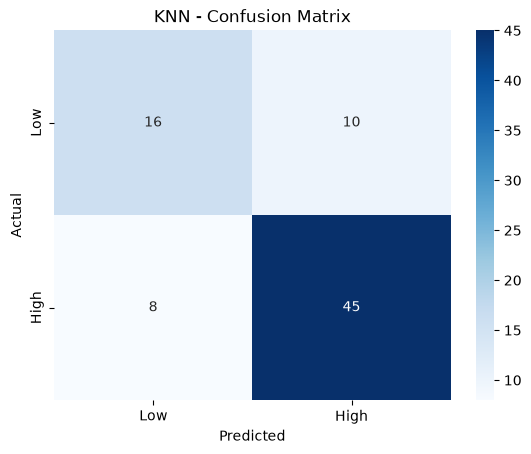


Decision Tree
                  precision    recall  f1-score   support

 Low Performance       0.71      0.96      0.82        26
High Performance       0.98      0.81      0.89        53

        accuracy                           0.86        79
       macro avg       0.85      0.89      0.85        79
    weighted avg       0.89      0.86      0.86        79

[[25  1]
 [10 43]]


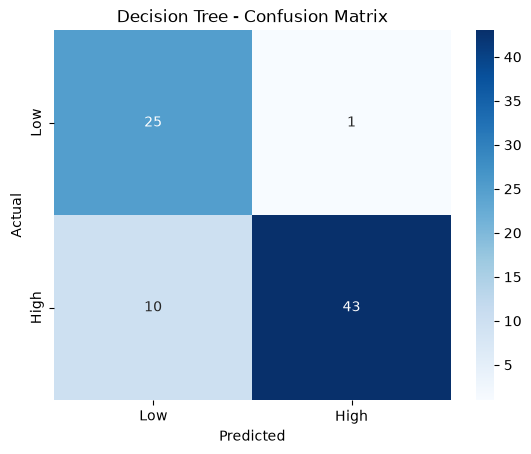


Random Forest
                  precision    recall  f1-score   support

 Low Performance       0.75      0.92      0.83        26
High Performance       0.96      0.85      0.90        53

        accuracy                           0.87        79
       macro avg       0.85      0.89      0.86        79
    weighted avg       0.89      0.87      0.88        79

[[24  2]
 [ 8 45]]


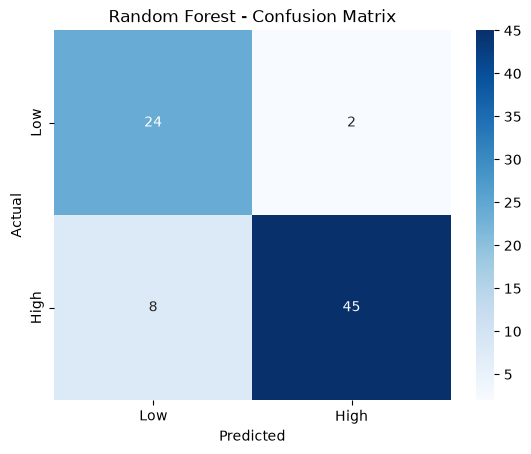


Logistic Regression
                  precision    recall  f1-score   support

 Low Performance       0.75      0.92      0.83        26
High Performance       0.96      0.85      0.90        53

        accuracy                           0.87        79
       macro avg       0.85      0.89      0.86        79
    weighted avg       0.89      0.87      0.88        79

[[24  2]
 [ 8 45]]


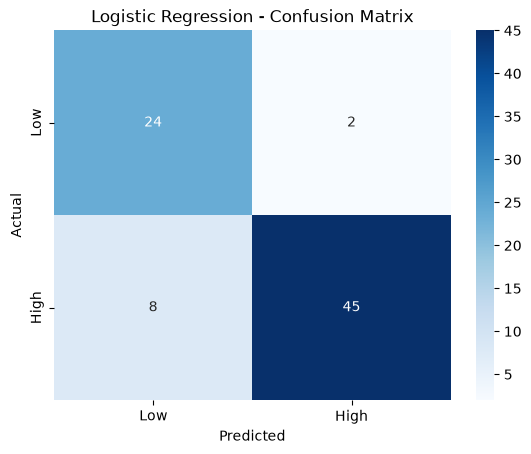


SVM
                  precision    recall  f1-score   support

 Low Performance       0.76      0.85      0.80        26
High Performance       0.92      0.87      0.89        53

        accuracy                           0.86        79
       macro avg       0.84      0.86      0.85        79
    weighted avg       0.87      0.86      0.86        79

[[22  4]
 [ 7 46]]


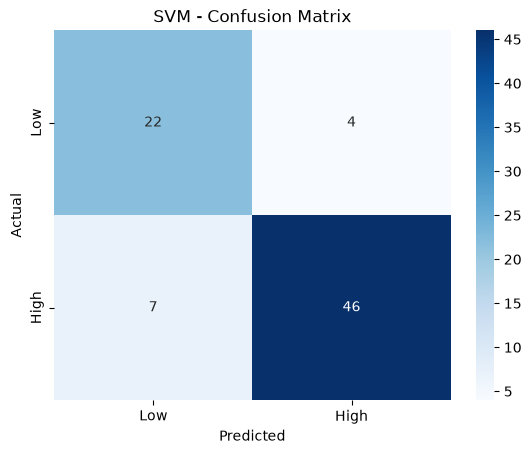

In [27]:
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

for name, pipeline in pipelines.items():
    y_pred = pipeline.predict(X_test)

    print(f"\n{name}")
    print(classification_report(
        y_test,
        y_pred,
        labels=[0, 1],
        target_names=["Low Performance", "High Performance"],
        zero_division=0
    ))

    cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
    print(cm)
    sns.heatmap(
        cm,
        annot=True,
        # fmt="d",
        cmap="Blues",
        xticklabels=["Low", "High"],
        yticklabels=["Low", "High"]
    )
    plt.title(f"{name} - Confusion Matrix")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.show()

## Baseline Results and Discussion

The Decision Tree achieved the highest accuracy (86.1%) and F1-score (0.887), outperforming KNN and Random Forest in these metrics. KNN achieved 81.0% accuracy, while Random Forest also achieved 81.0%.

These results provide a baseline for comparing model performance after hyperparameter tuning. Further evaluation will examine how well each model identifies both performance classes.

## Review 3: Hyperparameter Tuning and Model Evaluation

In this stage, KNN, Decision Tree, and Random Forest models are improved using `GridSearchCV` with 5-fold stratified cross-validation. Different hyperparameter combinations are tested to identify the best settings for each model. The tuned models are then evaluated on the test set using accuracy, precision, recall, F1-score, classification reports, and confusion matrices. Their results are compared with the baseline models to determine whether tuning improves performance.


KNN
Best CV Macro F1: 0.755
Best parameters: {'model__n_neighbors': 7, 'model__p': 2, 'model__weights': 'uniform'}
[[24  2]
 [ 6 47]]


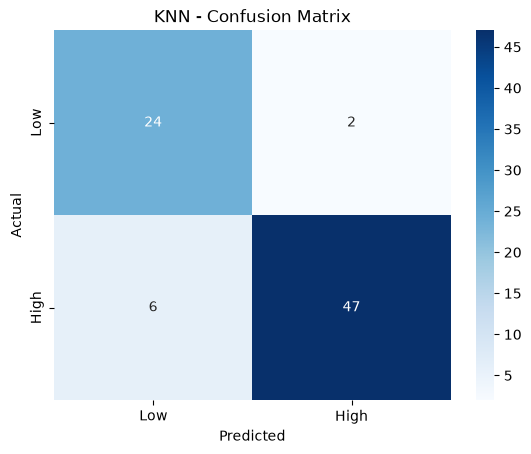


Decision Tree
Best CV Macro F1: 0.922
Best parameters: {'model__max_depth': 5, 'model__min_samples_leaf': 2, 'model__min_samples_split': 2}
[[24  2]
 [ 6 47]]


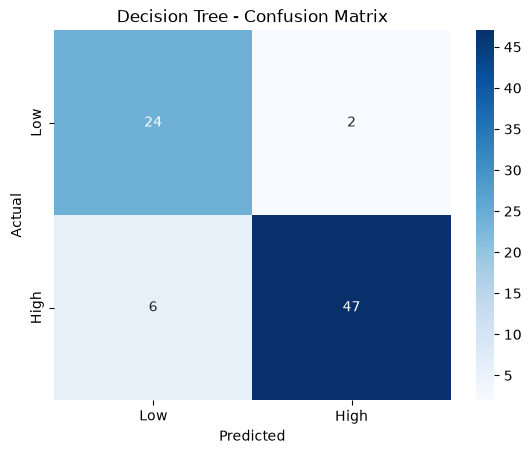


Random Forest
Best CV Macro F1: 0.914
Best parameters: {'model__max_depth': None, 'model__min_samples_leaf': 2, 'model__n_estimators': 200}
[[24  2]
 [ 6 47]]


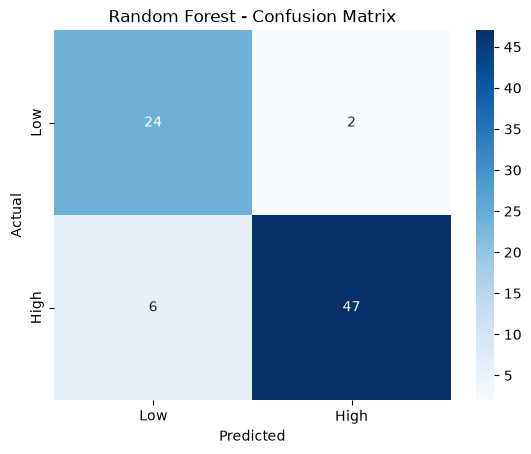


Logistic Regression
Best CV Macro F1: 0.911
Best parameters: {'model__C': 10, 'model__solver': 'liblinear'}
[[24  2]
 [ 6 47]]


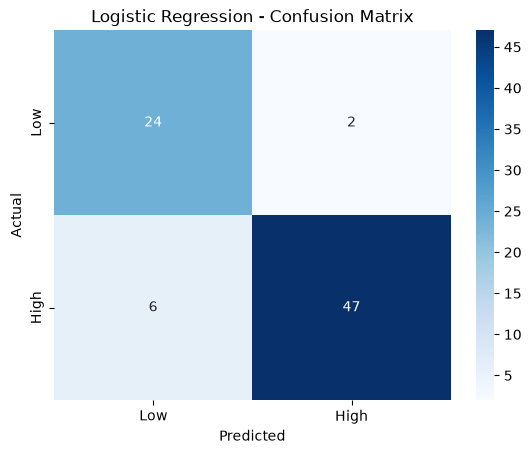


SVM
Best CV Macro F1: 0.889
Best parameters: {'model__C': 1, 'model__gamma': 'scale', 'model__kernel': 'linear'}
[[24  2]
 [ 6 47]]


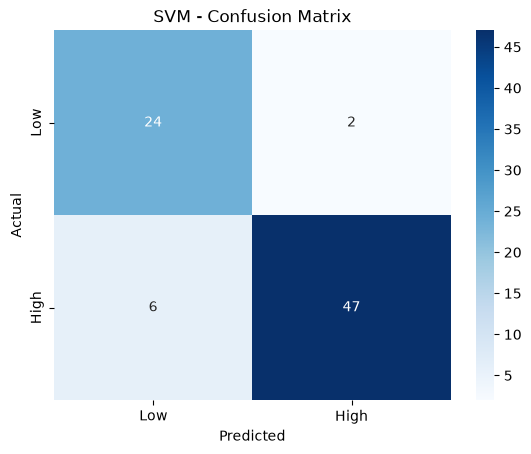


Naive Bayes
Best CV Macro F1: 0.783
Best parameters: {'model__var_smoothing': 1e-09}
[[24  2]
 [ 6 47]]


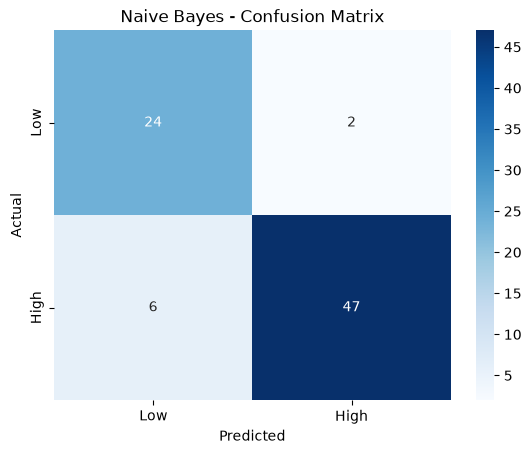


Neural Network
Best CV Macro F1: 0.781
Best parameters: {'model__activation': 'tanh', 'model__alpha': 0.0001, 'model__hidden_layer_sizes': (100, 50), 'model__learning_rate': 'constant'}
[[24  2]
 [ 6 47]]


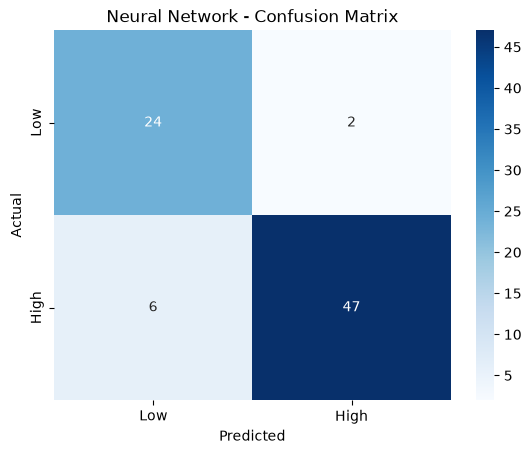

In [39]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.neural_network import MLPClassifier

# Use stratified 5-fold cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Define models and hyperparameters
param_grids = {
    "KNN": {
        "model__n_neighbors": [3, 5, 7, 9, 11],
        "model__weights": ["uniform", "distance"],
        "model__p": [1, 2]
    },
    "Decision Tree": {
        "model__max_depth": [None, 5, 10, 15],
        "model__min_samples_split": [2, 5, 10],
        "model__min_samples_leaf": [1, 2, 4]
    },
    "Random Forest": {
        "model__n_estimators": [100, 200],
        "model__max_depth": [None, 10, 20],
        "model__min_samples_leaf": [1, 2, 4]
    },
    "Logistic Regression": {
        "model__C": [0.01, 0.1, 1, 10],
        "model__solver": ["liblinear", "lbfgs"]
    },
    "SVM": {
        "model__C": [0.01, 0.1, 1, 10, 100],
        "model__kernel": ["linear", "rbf"],
        "model__gamma": ["scale", "auto", 0.01, 0.1, 1]
    },
    "Naive Bayes": {
        "model__var_smoothing": [1e-9, 1e-8, 1e-7, 1e-6, 1e-5]
    },
    "Neural Network": {
        "model__hidden_layer_sizes": [
            (50,),
            (100,),
            (50, 50),
            (100, 50)
        ],
        "model__activation": ["relu", "tanh"],
        "model__alpha": [0.0001, 0.001, 0.01],
        "model__learning_rate": ["constant", "adaptive"]
    }
}

models = {
    "KNN": KNeighborsClassifier(),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(random_state=42, n_jobs=1),
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "SVM": SVC(),
    "Naive Bayes": GaussianNB(),
    "Neural Network": MLPClassifier(
        max_iter=1000,
        random_state=42,
        early_stopping=True
    )
}

best_models = {}
tuning_results = []

for name, model in models.items():
    pipe = Pipeline([
        ("preprocessing", preprocessor),
        ("model", model)
    ])

    search = GridSearchCV(
        estimator=pipe,
        param_grid=param_grids[name],
        scoring="f1_macro",
        cv=cv,
        n_jobs=-1,
        refit=True
    )

    search.fit(X_train, y_train)

    best_models[name] = search.best_estimator_

    tuning_results.append({
        "Model": name,
        "Best CV Macro F1": round(search.best_score_, 3),
        "Best Parameters": search.best_params_
    })

    print(f"\n{name}")
    print("Best CV Macro F1:", round(search.best_score_, 3))
    print("Best parameters:", search.best_params_)
    cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
    print(cm)
    sns.heatmap(
        cm,
        annot=True,
        # fmt="d",
        cmap="Blues",
        xticklabels=["Low", "High"],
        yticklabels=["Low", "High"]
    )
    plt.title(f"{name} - Confusion Matrix")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.show()

In [40]:
import pandas as pd

tuning_df = pd.DataFrame(tuning_results)

tuning_df[
    ["Model", "Best CV Macro F1", "Best Parameters"]
]

,Model,Best CV Macro F1,Best Parameters
0,KNN,0.755,"{'model__n_neighbors': 7, 'model__p': 2, 'mode..."
1,Decision Tree,0.922,"{'model__max_depth': 5, 'model__min_samples_le..."
2,Random Forest,0.914,"{'model__max_depth': None, 'model__min_samples..."
3,Logistic Regression,0.911,"{'model__C': 10, 'model__solver': 'liblinear'}"
4,SVM,0.889,"{'model__C': 1, 'model__gamma': 'scale', 'mode..."
5,Naive Bayes,0.783,{'model__var_smoothing': 1e-09}
6,Neural Network,0.781,"{'model__activation': 'tanh', 'model__alpha': ..."


In [41]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)
import pandas as pd

evaluation_results = []

for name, model in best_models.items():
    y_pred = model.predict(X_test)

    evaluation_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Macro Precision": precision_score(
            y_test, y_pred, average="macro", zero_division=0
        ),
        "Macro Recall": recall_score(
            y_test, y_pred, average="macro", zero_division=0
        ),
        "Macro F1": f1_score(
            y_test, y_pred, average="macro", zero_division=0
        )
    })

    print(f"\n{'=' * 15} {name} {'=' * 15}")
    print(classification_report(
        y_test,
        y_pred,
        labels=[0, 1],
        target_names=["Low Performance", "High Performance"],
        zero_division=0
    ))
    print("Confusion Matrix:")
    print(confusion_matrix(y_test, y_pred, labels=[0, 1]))

tuned_results_df = pd.DataFrame(evaluation_results)
display(tuned_results_df.round(3))


=============== KNN ===============
                  precision    recall  f1-score   support

 Low Performance       0.73      0.62      0.67        26
High Performance       0.82      0.89      0.85        53

        accuracy                           0.80        79
       macro avg       0.78      0.75      0.76        79
    weighted avg       0.79      0.80      0.79        79

Confusion Matrix:
[[16 10]
 [ 6 47]]

=============== Decision Tree ===============
                  precision    recall  f1-score   support

 Low Performance       0.75      0.92      0.83        26
High Performance       0.96      0.85      0.90        53

        accuracy                           0.87        79
       macro avg       0.85      0.89      0.86        79
    weighted avg       0.89      0.87      0.88        79

Confusion Matrix:
[[24  2]
 [ 8 45]]

=============== Random Forest ===============
                  precision    recall  f1-score   support

 Low Performance       0.75      0

,Model,Accuracy,Macro Precision,Macro Recall,Macro F1
0,KNN,0.797,0.776,0.751,0.761
1,Decision Tree,0.873,0.854,0.886,0.864
2,Random Forest,0.873,0.854,0.886,0.864
3,Logistic Regression,0.873,0.854,0.886,0.864
4,SVM,0.899,0.880,0.905,0.889
5,Naive Bayes,0.747,0.712,0.704,0.707
6,Neural Network,0.873,0.857,0.857,0.857


In [36]:
from imblearn.over_sampling import RandomOverSampler, SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline
ros_pipeline = ImbPipeline([
    ("preprocessing", preprocessor),
    ("oversampling", RandomOverSampler(random_state=42)),
    ("model", SVC())
])

ros_grid = {
    "model__C": [0.1, 1, 10],
    "model__kernel": ["linear", "rbf"],
    "model__gamma": ["scale", "auto"]
}

ros_search = GridSearchCV(
    ros_pipeline,
    ros_grid,
    scoring="f1_macro",
    cv=cv,
    n_jobs=-1
)

ros_search.fit(X_train, y_train)

ros_pred = ros_search.best_estimator_.predict(X_test)

print("Best parameters:", ros_search.best_params_)
print(classification_report(
    y_test,
    ros_pred,
    target_names=["Low Performance", "High Performance"]
))
print(confusion_matrix(y_test, ros_pred))

Best parameters: {'model__C': 0.1, 'model__gamma': 'scale', 'model__kernel': 'linear'}
                  precision    recall  f1-score   support

 Low Performance       0.73      0.92      0.81        26
High Performance       0.96      0.83      0.89        53

        accuracy                           0.86        79
       macro avg       0.84      0.88      0.85        79
    weighted avg       0.88      0.86      0.86        79

[[24  2]
 [ 9 44]]


In [37]:
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline

smote_pipeline = ImbPipeline([
    ("preprocessing", preprocessor),
    ("smote", SMOTE(random_state=42)),
    ("model", SVC())
])

smote_grid = {
    "model__C": [0.1, 1, 10],
    "model__kernel": ["linear", "rbf"],
    "model__gamma": ["scale", "auto"]
}

smote_search = GridSearchCV(
    smote_pipeline,
    smote_grid,
    scoring="f1_macro",
    cv=cv,
    n_jobs=-1
)

smote_search.fit(X_train, y_train)

smote_pred = smote_search.best_estimator_.predict(X_test)

print("Best parameters:", smote_search.best_params_)
print(classification_report(
    y_test, smote_pred,
    target_names=["Low Performance", "High Performance"]
))
print("Confusion Matrix:")
print(confusion_matrix(y_test, smote_pred))

Best parameters: {'model__C': 0.1, 'model__gamma': 'scale', 'model__kernel': 'linear'}
                  precision    recall  f1-score   support

 Low Performance       0.71      0.92      0.80        26
High Performance       0.96      0.81      0.88        53

        accuracy                           0.85        79
       macro avg       0.83      0.87      0.84        79
    weighted avg       0.87      0.85      0.85        79

Confusion Matrix:
[[24  2]
 [10 43]]


In [38]:
weighted_pipeline = Pipeline([
    ("preprocessing", preprocessor),
    ("model", SVC(class_weight="balanced"))
])

weighted_grid = {
    "model__C": [0.1, 1, 10],
    "model__kernel": ["linear", "rbf"],
    "model__gamma": ["scale", "auto"]
}

weighted_search = GridSearchCV(
    weighted_pipeline,
    weighted_grid,
    scoring="f1_macro",
    cv=cv,
    n_jobs=-1
)

weighted_search.fit(X_train, y_train)

weighted_pred = weighted_search.best_estimator_.predict(X_test)

print(classification_report(
    y_test, weighted_pred,
    target_names=["Low Performance", "High Performance"]
))
print(confusion_matrix(y_test, weighted_pred))

                  precision    recall  f1-score   support

 Low Performance       0.69      0.92      0.79        26
High Performance       0.95      0.79      0.87        53

        accuracy                           0.84        79
       macro avg       0.82      0.86      0.83        79
    weighted avg       0.87      0.84      0.84        79

[[24  2]
 [11 42]]


## Hyperparameter Tuning and Evaluation Report

## Tuned Model Comparison and Discussion

Five machine-learning models—KNN, Decision Tree, Random Forest, Logistic Regression, and SVM—were evaluated after hyperparameter tuning using 5-fold stratified cross-validation.

SVM achieved the best test performance, with 89.9% accuracy and a macro F1-score of 0.889. It correctly classified 24 out of 26 Low Performance students and 47 out of 53 High Performance students.

Decision Tree, Random Forest, and Logistic Regression achieved the same test accuracy of 87.3%, while KNN achieved 79.7%.

Overall, SVM was the strongest model in this experiment because it achieved the highest accuracy and macro F1-score. It will be considered as the leading candidate for the final model selection.

## Class Imbalance Handling Using Random Oversampling

Random Oversampling was applied to the training data to address the class imbalance between Low Performance and High Performance students.

The oversampled SVM achieved 86.1% accuracy and a macro F1-score of 0.85, compared with 89.9% accuracy and 0.889 macro F1 for the original SVM.

The number of false positives remained at 2, while false negatives increased from 6 to 9. Therefore, Random Oversampling did not improve the overall performance of the SVM model in this experiment.